---
# <div align="center"><font color='red'>  </font></div>
# <div align="center"><font color='red'> COSC2779 | Deep Learning  </font></div>
## <div align="center"> <font color='red'> Week 11 Lecture Example: **Explaining Model Predictions** — LIME, SHAP & Transformer Attribution</font></div>
---

This week is about *why* a model made a prediction. We implement the main attribution methods from the lecture **from scratch** and apply them to a model where we **know the right answer** — so we can *check* which explanations are faithful.

1. **A model to explain** — a small Transformer on the Week 8 *marker-lookup* task.
2. **Perturbation methods** — leave-one-out, **LIME**, and **SHAP** (exact and KernelSHAP).
3. **Gradient methods** — gradient × input and **Integrated Gradients**.
4. **Transformer methods** — raw attention, **attention rollout**, and **gradient-weighted attention**.
5. **Which explanations are faithful?** — hit rates and deletion curves.
6. **A pitfall** — what happens when "removing" a token is out-of-distribution.

# Setup

In [1]:
import numpy as np, itertools, math
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.linear_model import Ridge

torch.manual_seed(0); np.random.seed(0)

# Part 1 — A model we can check

We reuse the Week 8 **marker-lookup** task. Each sequence is `[CLS]` followed by 8 tokens; one token is the **marker** `>`, and the **label is the token right after it**.

```
 C  2  2 11 10  9  3  >  4        -> label: 4
```

Why this task? **We know the ground truth.** The prediction depends only on the marker and the token after it — every other token is irrelevant. A faithful explanation must highlight those two positions.

We also add a special `PAD` token. During training, irrelevant tokens are randomly replaced by `PAD` (the label doesn't change), so the model learns that `PAD` means "nothing here". Perturbation methods will use `PAD` to "remove" a token.

In [2]:
VOCAB, CLS, MARKER, PAD = 13, 0, 1, 12      # content tokens 2..11
N_CLASS, L = 10, 8; S = L + 1                  # sequence = [CLS] + 8 tokens

def make_data(n):
    X = np.zeros((n, S), dtype=np.int64); y = np.zeros(n, dtype=np.int64)
    for i in range(n):
        c = np.random.randint(2, 12, size=L); m = np.random.randint(0, L - 1)
        c[m] = MARKER; y[i] = c[m + 1] - 2
        X[i, 0] = CLS; X[i, 1:] = c
    return X, y

X_train, y_train = make_data(6000)
X_test,  y_test  = make_data(1000)

def tok_str(t):
    return {CLS: 'C', MARKER: '>', PAD: '_'}.get(int(t), str(int(t)))
print(' '.join(tok_str(t) for t in X_test[0]), ' -> label token', y_test[0] + 2)

C 2 2 11 10 9 3 > 4  -> label token 4


### A small Transformer that keeps its attention maps (we need them in Part 4)

In [3]:
def sinusoid(L, d):
    pos = torch.arange(L)[:, None]; i = torch.arange(d)[None, :]
    ang = pos / (10000 ** ((i // 2 * 2) / d))
    pe = torch.zeros(L, d); pe[:, 0::2] = torch.sin(ang[:, 0::2]); pe[:, 1::2] = torch.cos(ang[:, 1::2])
    return pe

class MHA(nn.Module):
    def __init__(self, d, h):
        super().__init__(); self.h, self.dk = h, d // h
        self.q, self.k, self.v, self.o = (nn.Linear(d, d) for _ in range(4))
        self.attn = None                                   # stored for explanation
    def forward(self, x):
        B, T, d = x.shape
        sp = lambda t: t.view(B, T, self.h, self.dk).transpose(1, 2)
        Q, K, Vv = sp(self.q(x)), sp(self.k(x)), sp(self.v(x))
        A = torch.softmax(Q @ K.transpose(-2, -1) / self.dk ** 0.5, dim=-1)
        if A.requires_grad: A.retain_grad()                # keep dL/dA for Part 5
        self.attn = A
        return self.o((A @ Vv).transpose(1, 2).reshape(B, T, d))

class Block(nn.Module):
    def __init__(self, d, h, ff):
        super().__init__(); self.mha = MHA(d, h)
        self.n1, self.n2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.ff = nn.Sequential(nn.Linear(d, ff), nn.ReLU(), nn.Linear(ff, d))
    def forward(self, x):
        x = self.n1(x + self.mha(x)); return self.n2(x + self.ff(x))

class Classifier(nn.Module):
    def __init__(self, d=64, h=4, ff=128, n_layers=2):
        super().__init__(); self.emb = nn.Embedding(VOCAB, d)
        self.register_buffer('pe', sinusoid(S, d))
        self.blocks = nn.ModuleList([Block(d, h, ff) for _ in range(n_layers)])
        self.head = nn.Linear(d, N_CLASS)
    def forward(self, x=None, emb=None):              # emb= lets gradient methods feed embeddings
        h = (self.emb(x) if emb is None else emb) + self.pe[:S]
        for b in self.blocks: h = b(h)
        return self.head(h[:, 0])                      # classify from [CLS]

def train(pad_augment=True, epochs=15):
    torch.manual_seed(0)
    model = Classifier(); opt = torch.optim.Adam(model.parameters(), 1e-3)
    loader = DataLoader(TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train)), batch_size=128, shuffle=True)
    for _ in range(epochs):
        model.train()
        for xb, yb in loader:
            if pad_augment:     # replace ~20% of IRRELEVANT tokens by PAD
                pos = torch.arange(S)[None].expand_as(xb)
                mp = (xb == MARKER).float().argmax(1, keepdim=True)
                can = (pos >= 1) & (pos != mp) & (pos != mp + 1)
                xb = xb.masked_fill((torch.rand(xb.shape) < 0.2) & can, PAD)
            opt.zero_grad(); F.cross_entropy(model(xb), yb).backward(); opt.step()
    model.eval()
    with torch.no_grad():
        acc = (model(torch.from_numpy(X_test)).argmax(1) == torch.from_numpy(y_test)).float().mean().item()
    return model, acc

model, acc = train(pad_augment=True)
print(f'test accuracy: {acc:.3f}')

test accuracy: 1.000


The model solves the task. Now let's ask it *why*. Throughout, we explain the **probability of the predicted class**, and we pick one test example to look at closely.

In [4]:
def prob(model, xs, c):
    with torch.no_grad():
        return F.softmax(model(torch.from_numpy(np.asarray(xs))), -1)[:, c].numpy()

ex = 0
x, c = X_test[ex], int(y_test[ex])
marker_pos = int(np.where(x == MARKER)[0][0]); answer_pos = marker_pos + 1
print('sequence:', ' '.join(tok_str(t) for t in x))
print(f'marker at position {marker_pos}, answer at position {answer_pos}; p(correct) = {prob(model, x[None], c)[0]:.3f}')

def show_heatmap(scores_by_method, x, highlight=(marker_pos, answer_pos)):
    methods = list(scores_by_method)
    fig, ax = plt.subplots(figsize=(1.0 * len(x) + 2, 0.55 * len(methods) + 0.6))
    for r, name in enumerate(methods):
        s = np.asarray(scores_by_method[name], dtype=float).copy(); s[0] = 0   # ignore [CLS]
        m = np.abs(s).max() + 1e-9
        for j, t in enumerate(x):
            val = s[j] / m
            col = (1, 1 - max(val, 0), 1 - max(val, 0)) if val >= 0 else (1 + val, 1 + val, 1)
            ax.add_patch(plt.Rectangle((j, -r), 0.95, 0.9, color=col))
            ax.text(j + 0.47, -r + 0.45, tok_str(t), ha='center', va='center', fontsize=10,
                    fontweight='bold' if j in highlight else 'normal')
        ax.text(-0.2, -r + 0.45, name, ha='right', va='center', fontsize=10)
    ax.set_xlim(-2.8, len(x)); ax.set_ylim(-len(methods) + 0.8, 1.0); ax.axis('off')
    plt.title('token relevance  (red = supports the prediction, blue = against; bold = true evidence)', fontsize=9)
    plt.show()

sequence: C 2 2 11 10 9 3 > 4
marker at position 7, answer at position 8; p(correct) = 0.998


# Part 2 — Perturbation methods (model-agnostic)

These treat the model as a **black box**: change the input, watch the output. "Removing" a token means replacing it with `PAD`. `[CLS]` is never removed.

### Leave-one-out (occlusion)
Remove one token at a time: $R_i = f(x) - f(x_{\setminus i})$.

In [5]:
players = list(range(1, S))           # the 8 tokens after [CLS]

def remove(x, keep):                   # keep: bool per player
    z = x.copy()
    for j, p in enumerate(players):
        if not keep[j]: z[p] = PAD
    return z

def leave_one_out(model, x, c):
    base = prob(model, x[None], c)[0]; R = np.zeros(S)
    for p in players:
        z = x.copy(); z[p] = PAD; R[p] = base - prob(model, z[None], c)[0]
    return R

r_loo = leave_one_out(model, x, c)
print('LOO:', np.round(r_loo, 2), '  sum =', round(r_loo.sum(), 2))

LOO: [0.   0.   0.   0.   0.   0.   0.   0.99 1.  ]   sum = 1.99


Both the marker and the answer get a score of **1.0** — removing *either* one destroys the prediction. But the scores sum to **2**, although the prediction only moved by ~1. Leave-one-out **double-counts** when features work *together* (here: the marker is useless without the answer, and vice versa). Keep this in mind for SHAP.

### LIME (from scratch)
1. Sample many random subsets of tokens to keep (a binary vector $z$).
2. Query the model on each perturbed sequence.
3. Weight each sample by how close it is to the original (fewer removals = closer).
4. Fit a weighted linear model $g(z) = w_0 + \sum_j w_j z_j$; the weights are the explanation.

In [6]:
def lime(model, x, c, n_samples=500, kernel_width=0.25, seed=0):
    rng = np.random.default_rng(seed)
    M = len(players)
    Z = rng.random((n_samples, M)) > 0.5; Z[0] = True               # random keep/remove masks
    ys = prob(model, np.stack([remove(x, z) for z in Z]), c)       # query the black box
    dist = 1 - Z.mean(1)                                           # fraction removed
    w = np.exp(-dist ** 2 / kernel_width ** 2)                     # locality weights
    g = Ridge(alpha=0.01).fit(Z.astype(float), ys, sample_weight=w)
    R = np.zeros(S); R[players] = g.coef_
    return R

r_lime = lime(model, x, c)
print('LIME:', np.round(r_lime, 2))

LIME: [ 0.    0.   -0.   -0.03  0.01 -0.   -0.03  0.83  0.8 ]


### SHAP — exact Shapley values
With only 8 tokens there are $2^8 = 256$ coalitions, so we can compute **exact** Shapley values using the lecture's formula, with tokens as players and "removed" = `PAD`:
$$\phi_i = \sum_{S \subseteq F\setminus\{i\}} \frac{|S|!\,(|F|-|S|-1)!}{|F|!}\,\big[v(S\cup\{i\}) - v(S)\big].$$

In [7]:
def exact_shap(model, x, c):
    M = len(players)
    coalitions = np.array(list(itertools.product([0, 1], repeat=M)), dtype=bool)
    values = prob(model, np.stack([remove(x, k) for k in coalitions]), c)
    v = {tuple(k): val for k, val in zip(coalitions, values)}
    phi = np.zeros(S)
    for j in range(M):
        for k in coalitions:
            if k[j]: continue
            k2 = k.copy(); k2[j] = True; s = k.sum()
            weight = math.factorial(s) * math.factorial(M - s - 1) / math.factorial(M)
            phi[players[j]] += weight * (v[tuple(k2)] - v[tuple(k)])
    return phi, v[tuple([True] * M)], v[tuple([False] * M)]

r_shap, f_full, f_empty = exact_shap(model, x, c)
print('SHAP:', np.round(r_shap, 2))
print(f'sum = {r_shap.sum():.3f}   f(x) - f(all removed) = {f_full - f_empty:.3f}')

SHAP: [ 0.  -0.   0.  -0.   0.  -0.  -0.   0.5  0.5]
sum = 0.997   f(x) - f(all removed) = 0.997


SHAP gives the marker and the answer **0.5 each**: they are equally necessary, so **symmetry** splits the credit, and the values **sum exactly** to the change in prediction (**efficiency**). Compare with leave-one-out's 1.0 + 1.0. This is the fairness property from the lecture, visible in numbers.

### KernelSHAP — SHAP when exact is too expensive
With $M$ features exact SHAP needs $2^M$ evaluations. **KernelSHAP** samples coalitions (randomly, so the result is an *approximation*) and fits a weighted linear model — LIME, but with the **Shapley kernel** as the weighting and the constraint that values sum to $f(x) - f(\varnothing)$:
$$\pi(z) \propto \frac{M-1}{\binom{M}{|z|}\,|z|\,(M-|z|)}.$$

In [8]:
def kernel_shap(model, x, c, n_samples=500, seed=0):
    rng = np.random.default_rng(seed); M = len(players)
    sizes = np.arange(1, M)
    pw = (M - 1) / (np.array([math.comb(M, k) for k in sizes]) * sizes * (M - sizes)); pw /= pw.sum()
    Z = np.zeros((n_samples, M), bool)
    for i in range(n_samples):                                   # sample coalition sizes by the Shapley kernel
        Z[i, rng.choice(M, rng.choice(sizes, p=pw), replace=False)] = True
    ys = prob(model, np.stack([remove(x, z) for z in Z]), c)
    f0 = prob(model, remove(x, np.zeros(M, bool))[None], c)[0]; f1 = prob(model, x[None], c)[0]
    # least squares with the efficiency constraint sum(phi) = f1 - f0 (eliminate the last variable)
    A = Z[:, :-1].astype(float) - Z[:, [-1]].astype(float)
    t = ys - f0 - Z[:, -1] * (f1 - f0)
    coef = np.linalg.lstsq(A, t, rcond=None)[0]
    R = np.zeros(S); R[players] = np.append(coef, (f1 - f0) - coef.sum())
    return R

r_kshap = kernel_shap(model, x, c)
print('KernelSHAP:', np.round(r_kshap, 2))
print('exact SHAP:', np.round(r_shap, 2))
corrs = [np.corrcoef(kernel_shap(model, X_test[i], int(y_test[i]))[1:],
                     exact_shap(model, X_test[i], int(y_test[i]))[0][1:])[0, 1] for i in range(20)]
print(f'agreement with exact SHAP over 20 sequences: mean correlation = {np.mean(corrs):.3f}')

KernelSHAP: [ 0.   -0.01 -0.   -0.03  0.01 -0.02  0.01  0.6   0.42]
exact SHAP: [ 0.  -0.   0.  -0.   0.  -0.  -0.   0.5  0.5]
agreement with exact SHAP over 20 sequences: mean correlation = 0.986


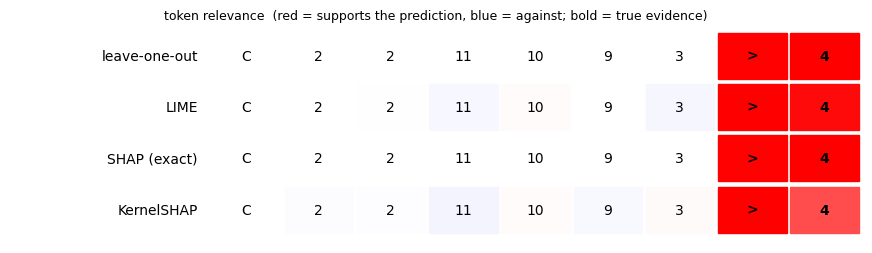

In [9]:
show_heatmap({'leave-one-out': r_loo, 'LIME': r_lime, 'SHAP (exact)': r_shap, 'KernelSHAP': r_kshap}, x)

# Part 3 — Gradient methods

These need access to the model's gradients, but only one (or a few) backward passes. Tokens are discrete, so we differentiate with respect to their **embeddings**.

**Gradient × input**: $R_i = \sum_d \frac{\partial f}{\partial e_{i,d}}\, e_{i,d}$.

In [10]:
def grad_x_input(model, x, c):
    e = model.emb(torch.from_numpy(x[None])).detach().requires_grad_(True)
    F.softmax(model(emb=e), -1)[0, c].backward()
    return (e.grad * e).sum(-1)[0].detach().numpy()

r_gxi = grad_x_input(model, x, c)
print('grad x input:', np.round(r_gxi, 4))

grad x input: [-0.0001 -0.     -0.      0.     -0.0004 -0.0001 -0.      0.0003  0.0008]


Tiny numbers! The model is ~100% confident, so the softmax is **saturated**: nudging the input barely changes the output, and the local gradient is almost zero. The gradient only sees the *local* slope, not the whole journey from "no evidence" to "confident".

**Integrated Gradients** fixes this by accumulating gradients along a straight path from a **baseline** $e'$ (here: all tokens replaced by `PAD`, keeping `[CLS]`) to the input:
$$R_i = (e_i - e_i')\cdot \int_0^1 \frac{\partial f\big(e' + \alpha(e-e')\big)}{\partial e_i}\,d\alpha .$$

In [11]:
def integrated_gradients(model, x, c, steps=200):
    xb = x.copy(); xb[1:] = PAD                                   # baseline: keep [CLS], rest PAD
    e  = model.emb(torch.from_numpy(x[None])).detach()
    eb = model.emb(torch.from_numpy(xb[None])).detach()
    total = torch.zeros_like(e)
    for a in (torch.arange(steps) + 0.5) / steps:                 # midpoint Riemann sum
        ea = (eb + a * (e - eb)).requires_grad_(True)
        F.softmax(model(emb=ea), -1)[0, c].backward(); total += ea.grad
    R = ((e - eb) * total / steps).sum(-1)[0].numpy()
    return R, prob(model, x[None], c)[0] - prob(model, xb[None], c)[0]

r_ig, gap = integrated_gradients(model, x, c)
print('IG:', np.round(r_ig, 2))
print(f'sum = {r_ig.sum():.3f}   f(x) - f(baseline) = {gap:.3f}   (completeness)')

IG: [ 0.    0.    0.   -0.01 -0.   -0.    0.09  0.73  0.19]
sum = 0.996   f(x) - f(baseline) = 0.997   (completeness)


IG recovers the signal on the marker and the answer, and its scores **sum to $f(x) - f(\text{baseline})$** (completeness) — the gradient analogue of SHAP's efficiency. Unlike SHAP it doesn't split credit equally: it depends on the path and the baseline.

# Part 4 — Transformer-specific methods

### Raw attention
Our model stores each layer's attention. Let's look at every head.

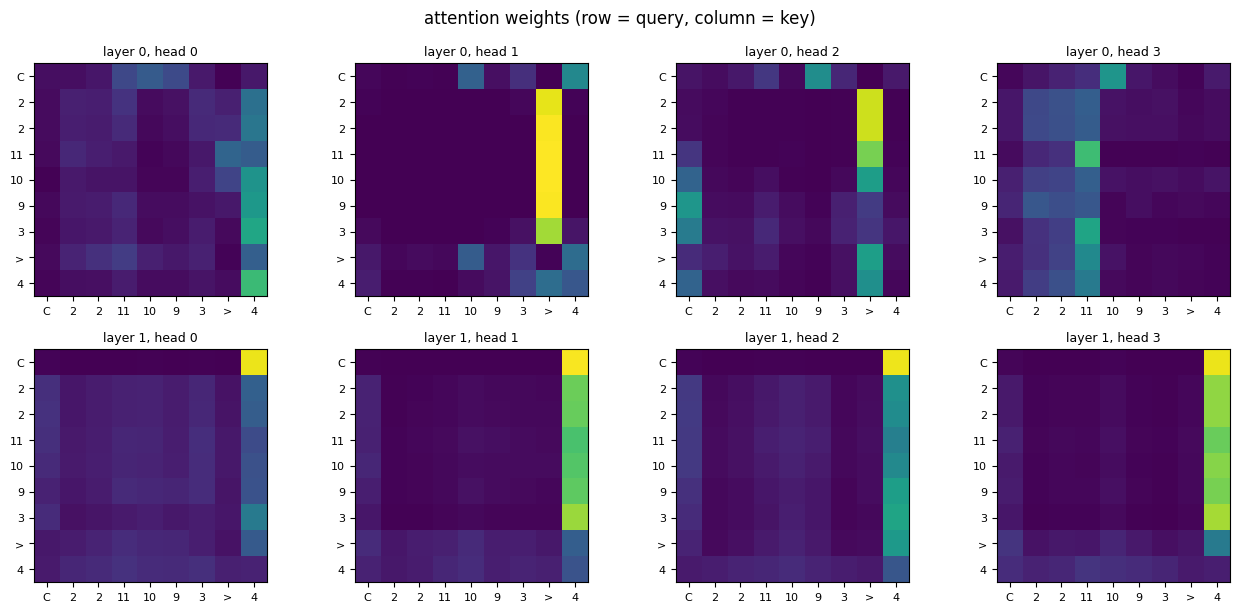

In [12]:
with torch.no_grad():
    model(torch.from_numpy(x[None]))
labels = [tok_str(t) for t in x]
fig, axes = plt.subplots(2, 4, figsize=(13, 6.2))
for l, blk in enumerate(model.blocks):
    for h in range(4):
        ax = axes[l, h]; ax.imshow(blk.mha.attn[0, h].numpy(), cmap='viridis', vmin=0, vmax=1)
        ax.set_xticks(range(S)); ax.set_xticklabels(labels, fontsize=8)
        ax.set_yticks(range(S)); ax.set_yticklabels(labels, fontsize=8)
        ax.set_title(f'layer {l}, head {h}', fontsize=9)
plt.suptitle('attention weights (row = query, column = key)'); plt.tight_layout(); plt.show()

Look at the **top row** (`[CLS]` as the query) of the last layer: it concentrates on the answer position. Earlier layers show heads attending from the answer to the marker — the model first *marks* the token after `>`, then `[CLS]` *copies* it.

Raw attention works well here because the task is literally "copy one token". In general it shows **where information flows, not how much it mattered** — so we also compute:

- **Attention rollout**: average heads, add the identity for the residual connection, multiply through the layers.
- **Gradient-weighted attention** (Chefer et al.): weight attention by its gradient for the target class, keep positive parts, and accumulate $R \leftarrow R + \bar{A} R$ — class-specific, like Grad-CAM.

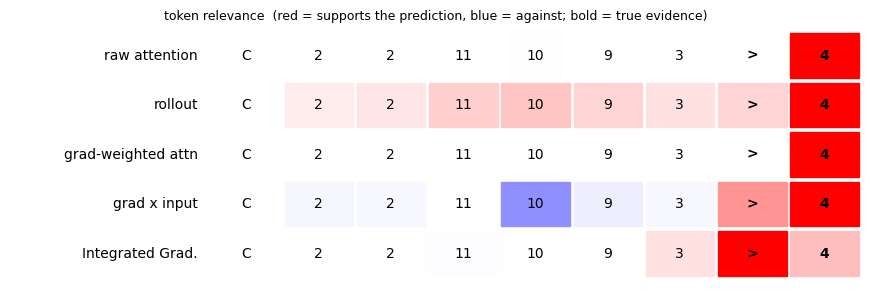

In [13]:
def raw_attention(model, x, c):
    with torch.no_grad(): model(torch.from_numpy(x[None]))
    return model.blocks[-1].mha.attn[0].mean(0)[0].numpy()        # last layer, head-avg, [CLS] row

def attention_rollout(model, x, c):
    with torch.no_grad(): model(torch.from_numpy(x[None]))
    R = torch.eye(S)
    for blk in model.blocks:
        a = blk.mha.attn[0].mean(0)                                 # average heads
        a = 0.5 * a + 0.5 * torch.eye(S); a = a / a.sum(-1, keepdim=True)   # residual
        R = a @ R
    return R[0].numpy()

def gradient_weighted_attention(model, x, c):
    out = model(torch.from_numpy(x[None])); model.zero_grad()
    F.softmax(out, -1)[0, c].backward()
    R = torch.eye(S)
    for blk in model.blocks:
        A = blk.mha.attn                                            # (1, heads, S, S), grad retained
        cam = (A.grad[0] * A[0]).clamp(min=0).mean(0).detach()     # E_h[(grad ⊙ A)^+]
        R = R + cam @ R
    return (R - torch.eye(S))[0].numpy()

r_att, r_roll, r_gatt = raw_attention(model, x, c), attention_rollout(model, x, c), gradient_weighted_attention(model, x, c)
show_heatmap({'raw attention': r_att, 'rollout': r_roll, 'grad-weighted attn': r_gatt,
              'grad x input': r_gxi, 'Integrated Grad.': r_ig}, x)

Rollout spreads some relevance over many tokens (it is class-agnostic and includes the residual paths); gradient-weighted attention is sharper and class-specific.

# Part 5 — Which explanations are faithful?

Because we know the truth, we can **score** each method.

**Test 1 — hit rate**: over 100 test sequences, how often is the method's top-ranked token the marker or the answer?

In [14]:
methods = {
    'leave-one-out':      lambda x, c: leave_one_out(model, x, c),
    'LIME':               lambda x, c: lime(model, x, c),
    'SHAP (exact)':       lambda x, c: exact_shap(model, x, c)[0],
    'grad x input':       lambda x, c: grad_x_input(model, x, c),
    'Integrated Grad.':   lambda x, c: integrated_gradients(model, x, c, steps=64)[0],
    'raw attention':      lambda x, c: raw_attention(model, x, c),
    'attention rollout':  lambda x, c: attention_rollout(model, x, c),
    'grad-weighted attn': lambda x, c: gradient_weighted_attention(model, x, c),
}
def hit_rate(fn, n=100):
    hits = 0
    for i in range(n):
        xi, ci = X_test[i], int(y_test[i]); a = int(np.where(xi == MARKER)[0][0]) + 1
        r = np.asarray(fn(xi, ci), dtype=float).copy(); r[0] = -np.inf
        hits += int(np.argmax(r) in (a - 1, a))
    return hits / n
rates = {name: hit_rate(fn) for name, fn in methods.items()}
for name, r in rates.items(): print(f'{name:20s} {r:.2f}')

leave-one-out        1.00
LIME                 0.99
SHAP (exact)         0.97
grad x input         0.85
Integrated Grad.     0.86
raw attention        1.00
attention rollout    1.00
grad-weighted attn   1.00


**Test 2 — deletion curve** (the lecture's faithfulness check): remove tokens in order of relevance and watch $p(\text{correct})$. A faithful explanation makes it **collapse fastest**; a random order is the reference.

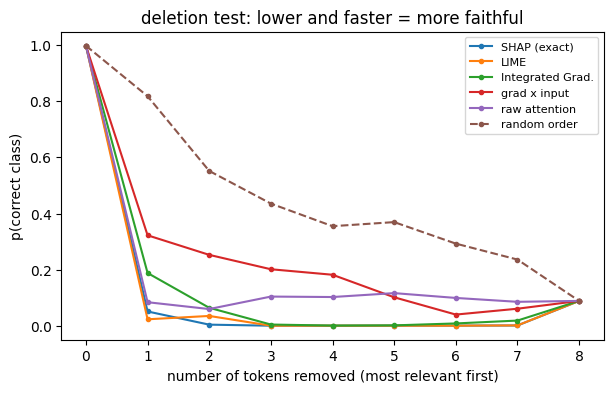

In [15]:
def deletion_curve(fn, n=60):
    curves = []
    for i in range(n):
        xi, ci = X_test[i], int(y_test[i])
        order = np.argsort(-np.asarray(fn(xi, ci))[1:]) + 1
        z = xi.copy(); curve = [prob(model, z[None], ci)[0]]
        for p in order:
            z[p] = PAD; curve.append(prob(model, z[None], ci)[0])
        curves.append(curve)
    return np.mean(curves, 0)

rng = np.random.default_rng(0)
to_plot = {k: methods[k] for k in ['SHAP (exact)', 'LIME', 'Integrated Grad.', 'grad x input', 'raw attention']}
to_plot['random order'] = lambda x, c: rng.random(S)
plt.figure(figsize=(7, 4))
for name, fn in to_plot.items():
    plt.plot(deletion_curve(fn), marker='o', ms=3, label=name, ls='--' if name == 'random order' else '-')
plt.xlabel('number of tokens removed (most relevant first)'); plt.ylabel('p(correct class)')
plt.title('deletion test: lower and faster = more faithful'); plt.legend(fontsize=8); plt.show()

**What is your judgment?** SHAP, LIME and leave-one-out find the evidence almost every time; the attention-based methods do too on this simple copy task. Gradient × input is the weakest because of saturation, and IG repairs it. On a real model you *can't* compute a hit rate — there is no ground truth — which is why the **deletion test** is the practical tool.

# Part 6 — A pitfall: when "removing" is out-of-distribution

Our model was trained with `PAD` masking, so replacing a token by `PAD` means "no information". What if the model had **never** seen `PAD`? Then every perturbed input is **out-of-distribution**, and the model's response to it can be arbitrary. Let's train the same model *without* the augmentation and explain the same example.

test accuracy (no PAD augmentation): 1.000


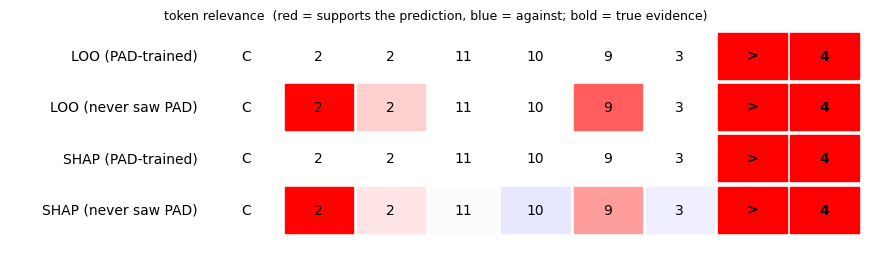

In [16]:
model_no_pad, acc2 = train(pad_augment=False)
print(f'test accuracy (no PAD augmentation): {acc2:.3f}')

show_heatmap({'LOO (PAD-trained)':  leave_one_out(model, x, c),
              'LOO (never saw PAD)': leave_one_out(model_no_pad, x, c),
              'SHAP (PAD-trained)':  exact_shap(model, x, c)[0],
              'SHAP (never saw PAD)': exact_shap(model_no_pad, x, c)[0]}, x)

Both models are equally accurate on real data, but the explanations of the second one can credit **irrelevant tokens**: removing them produces an unfamiliar input that disturbs the model. The explanation then reflects the model's reaction to the *perturbation*, not its reasoning on real data. This is the LIME/SHAP weakness from the lecture — **the result depends on how you "remove" a feature** (the baseline / masking choice).

# Wrap-up

| Method | Needs | Key property | Watch out for |
|---|---|---|---|
| Leave-one-out | black box | simple | double-counts interacting features |
| LIME | black box | local linear surrogate | sampling noise, kernel width |
| SHAP (exact / Kernel) | black box | fair split, sums to prediction | cost; masking/baseline choice |
| Gradient × input | gradients | one backward pass | saturation |
| Integrated Gradients | gradients | completeness | baseline choice |
| Raw attention / rollout | attention maps | cheap, shows information flow | not importance; class-agnostic |
| Gradient-weighted attention | attention + gradients | class-specific | heuristic combination |

**Exercises**
* Use a different IG baseline (e.g. all-zero embeddings). Do the attributions change? Does completeness still hold?
* Increase LIME's `kernel_width` to 1.0 or reduce `n_samples` to 50 — how stable is the explanation across random seeds?
* Make the label depend on **two** tokens after the marker (e.g. their sum mod 10). How does SHAP split the credit now?
* Replace `PAD` by a random content token as the "removal" — what happens to leave-one-out and SHAP?